In [3]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load uploaded CSV files
X_df = pd.read_csv("/content/dataSet_withFeatures (2).csv", header=None)
y_df = pd.read_csv("/content/dataSet_withFeatures_labels (1).csv", header=None)

# The last column of the feature CSV contains the terrain label.
X = X_df.iloc[:, :-1].astype(np.float32).copy()
y = X_df.iloc[:, -1].astype(str).copy()

# Verify the separate label file
assert y.astype(str).reset_index(drop=True).equals(
    y_df.iloc[:, 0].astype(str).reset_index(drop=True)
), "The two label sources do not match!"

assert X.shape == (5990, 447), f"Unexpected feature shape: {X.shape}"
assert not X.isna().any().any(), "Missing feature values detected!"
assert np.isfinite(X.to_numpy()).all(), "Non-finite feature values detected!"

print("Dataset shape:", X.shape)
print("Number of classes:", y.nunique())
print("\nClass distribution:\n", y.value_counts())


Device: cpu
Dataset shape: (5990, 447)
Number of classes: 8

Class distribution:
 447
asphalt          798
lab              775
laminate_wood    772
sand             760
cork             732
gravel           727
pebble           725
grass            701
Name: count, dtype: int64


In [4]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

class_names = sorted(y.unique())
label_to_id = {name: i for i, name in enumerate(class_names)}
id_to_label = {i: name for name, i in label_to_id.items()}

# Encode labels consistently for PyTorch
y_train_id = y_train.map(label_to_id).to_numpy(dtype=np.int64)
y_val_id = y_val.map(label_to_id).to_numpy(dtype=np.int64)
y_test_id = y_test.map(label_to_id).to_numpy(dtype=np.int64)

print("Classes:", class_names)
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


Classes: ['asphalt', 'cork', 'grass', 'gravel', 'lab', 'laminate_wood', 'pebble', 'sand']
Training: 4193
Validation: 898
Test: 899


In [5]:

baseline_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=10, kernel="rbf", gamma="scale"))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )
}

baseline_results = []
for name, model in baseline_models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)

    baseline_results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        )
    })

baseline_results_df = pd.DataFrame(baseline_results).sort_values(
    "Validation Accuracy", ascending=False
)
display(baseline_results_df)


Training: Logistic Regression
Training: SVM (RBF)
Training: Random Forest


,Model,Validation Accuracy,Validation Macro F1
2,Random Forest,0.798441,0.796056
1,SVM (RBF),0.712695,0.713704
0,Logistic Regression,0.571269,0.571897


In [6]:

# Convert the data splits to NumPy arrays
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Tactile readings: 414 values per sample -> (6 channels, 1, 69)
xtr_raw = X_train_np[:, :414].reshape(-1, 6, 1, 69)
xva_raw = X_val_np[:, :414].reshape(-1, 6, 1, 69)
xte_raw = X_test_np[:, :414].reshape(-1, 6, 1, 69)

# All 33 engineered features
ftr_raw = X_train_np[:, 414:447]
fva_raw = X_val_np[:, 414:447]
fte_raw = X_test_np[:, 414:447]

# Normalize each tactile channel using training data only
channel_mean = xtr_raw.mean(axis=(0, 2, 3), keepdims=True)
channel_std = xtr_raw.std(axis=(0, 2, 3), keepdims=True)
channel_std[channel_std == 0] = 1.0

xtr = (xtr_raw - channel_mean) / channel_std
xva = (xva_raw - channel_mean) / channel_std
xte = (xte_raw - channel_mean) / channel_std

# Normalize all engineered features using training data only
feature_mean = ftr_raw.mean(axis=0, keepdims=True)
feature_std = ftr_raw.std(axis=0, keepdims=True)
feature_std[feature_std == 0] = 1.0

ftr = (ftr_raw - feature_mean) / feature_std
fva = (fva_raw - feature_mean) / feature_std
fte = (fte_raw - feature_mean) / feature_std

print("Tactile shapes:", xtr.shape, xva.shape, xte.shape)
print("Feature shapes:", ftr.shape, fva.shape, fte.shape)
print("Finite values:", all(
    np.isfinite(a).all() for a in [xtr, xva, xte, ftr, fva, fte]
))


Tactile shapes: (4193, 6, 1, 69) (898, 6, 1, 69) (899, 6, 1, 69)
Feature shapes: (4193, 33) (898, 33) (899, 33)
Finite values: True


In [7]:

BATCH_SIZE = 64

train_dataset = TensorDataset(
    torch.tensor(xtr, dtype=torch.float32),
    torch.tensor(ftr, dtype=torch.float32),
    torch.tensor(y_train_id, dtype=torch.long)
)

val_dataset = TensorDataset(
    torch.tensor(xva, dtype=torch.float32),
    torch.tensor(fva, dtype=torch.float32),
    torch.tensor(y_val_id, dtype=torch.long)
)

test_dataset = TensorDataset(
    torch.tensor(xte, dtype=torch.float32),
    torch.tensor(fte, dtype=torch.float32),
    torch.tensor(y_test_id, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Verify dimensions of a batch
xb, fb, yb = next(iter(train_loader))
print("Batch tactile shape:", xb.shape)
print("Batch engineered feature shape:", fb.shape)
print("Batch label shape:", yb.shape)


Train batches: 66
Validation batches: 15
Test batches: 15
Batch tactile shape: torch.Size([64, 6, 1, 69])
Batch engineered feature shape: torch.Size([64, 33])
Batch label shape: torch.Size([64])


In [8]:

class TerrainCNN(nn.Module):
    def __init__(self, num_classes=8, num_features=33):
        super().__init__()

        self.conv1 = nn.Conv2d(
            6, 24, kernel_size=(1, 5), padding=(0, 1)
        )
        self.conv2 = nn.Conv2d(
            24, 24, kernel_size=(1, 5), padding=(0, 1)
        )
        self.conv3 = nn.Conv2d(
            24, 24, kernel_size=(1, 5), padding=(0, 1)
        )
        self.conv4 = nn.Conv2d(
            24, 24, kernel_size=(1, 5), padding=(0, 1)
        )

        self.pool = nn.MaxPool2d(kernel_size=(1, 2), stride=1)
        self.dropout = nn.Dropout(p=0.5)

        # 24 feature maps * 57 positions + 33 engineered features
        self.fc1 = nn.Linear(24 * 57 + num_features, 50)
        self.fc2 = nn.Linear(50, num_classes)

    def forward(self, x, features):
        x = self.dropout(self.pool(torch.relu(self.conv1(x))))
        x = self.dropout(self.pool(torch.relu(self.conv2(x))))
        x = self.dropout(self.pool(torch.relu(self.conv3(x))))
        x = self.dropout(self.pool(torch.relu(self.conv4(x))))

        x = x.flatten(start_dim=1)
        x = torch.cat((x, features), dim=1)

        x = torch.relu(self.fc1(x))
        return self.fc2(x)


# Shape test before training
model = TerrainCNN().to(device)

with torch.no_grad():
    sample_logits = model(xb.to(device), fb.to(device))

print("Model output shape:", sample_logits.shape)
print("Expected:", (xb.shape[0], 8))


Model output shape: torch.Size([64, 8])
Expected: (64, 8)


In [9]:

import copy

model = TerrainCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 100
PATIENCE = 12

best_val_acc = -1.0
best_state = None
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    # Training
    model.train()
    running_loss = 0.0

    for xb, fb, yb in train_loader:
        xb = xb.to(device)
        fb = fb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb, fb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * yb.size(0)

    train_loss = running_loss / len(train_dataset)

    # Validation
    model.eval()
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for xb, fb, yb in val_loader:
            logits = model(xb.to(device), fb.to(device))
            val_preds.extend(logits.argmax(dim=1).cpu().numpy())
            val_labels.extend(yb.numpy())

    val_acc = accuracy_score(val_labels, val_preds)
    val_macro_f1 = f1_score(
        val_labels, val_preds, average="macro"
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_macro_f1
    })

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val accuracy: {val_acc:.2%} | "
            f"Val macro F1: {val_macro_f1:.4f}"
        )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

model.load_state_dict(best_state)
model.eval()

print(f"\nBest validation accuracy: {best_val_acc:.2%}")
torch.save(model.state_dict(), "/content/terrain_cnn.pth")


Epoch   1 | Loss: 2.0426 | Val accuracy: 31.07% | Val macro F1: 0.1970
Epoch   5 | Loss: 1.6079 | Val accuracy: 38.64% | Val macro F1: 0.3286
Epoch  10 | Loss: 1.3215 | Val accuracy: 43.21% | Val macro F1: 0.3732
Epoch  15 | Loss: 1.2004 | Val accuracy: 52.23% | Val macro F1: 0.4881
Epoch  20 | Loss: 1.1155 | Val accuracy: 53.23% | Val macro F1: 0.4940
Epoch  25 | Loss: 1.0528 | Val accuracy: 54.12% | Val macro F1: 0.5032
Epoch  30 | Loss: 0.9938 | Val accuracy: 56.68% | Val macro F1: 0.5308
Epoch  35 | Loss: 0.9692 | Val accuracy: 59.24% | Val macro F1: 0.5611
Epoch  40 | Loss: 0.9316 | Val accuracy: 59.91% | Val macro F1: 0.5708
Epoch  45 | Loss: 0.8986 | Val accuracy: 60.58% | Val macro F1: 0.5706
Epoch  50 | Loss: 0.8769 | Val accuracy: 61.92% | Val macro F1: 0.5879
Epoch  55 | Loss: 0.8527 | Val accuracy: 61.80% | Val macro F1: 0.5852
Epoch  60 | Loss: 0.8272 | Val accuracy: 62.47% | Val macro F1: 0.5910
Epoch  65 | Loss: 0.8138 | Val accuracy: 62.14% | Val macro F1: 0.5905
Epoch 

CNN validation accuracy: 63.59%
CNN validation macro F1: 0.6082

Classification report:
               precision    recall  f1-score   support

      asphalt       0.70      0.48      0.57       119
         cork       0.76      0.15      0.24       110
        grass       0.66      0.87      0.75       105
       gravel       0.74      0.61      0.67       109
          lab       0.59      0.56      0.58       116
laminate_wood       0.59      0.77      0.66       116
       pebble       0.56      0.68      0.61       109
         sand       0.65      0.99      0.78       114

     accuracy                           0.64       898
    macro avg       0.66      0.64      0.61       898
 weighted avg       0.66      0.64      0.61       898



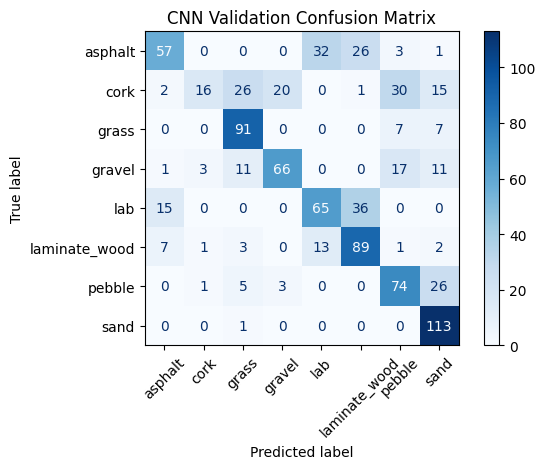

In [10]:

model.eval()
val_preds = []
val_labels = []

with torch.no_grad():
    for xb, fb, yb in val_loader:
        logits = model(xb.to(device), fb.to(device))
        val_preds.extend(logits.argmax(dim=1).cpu().numpy())
        val_labels.extend(yb.numpy())

print("CNN validation accuracy:", f"{accuracy_score(val_labels, val_preds):.2%}")
print("CNN validation macro F1:", f"{f1_score(val_labels, val_preds, average='macro'):.4f}")

print("\nClassification report:")
print(classification_report(
    val_labels,
    val_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    val_labels,
    val_preds,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("CNN Validation Confusion Matrix")
plt.tight_layout()
plt.show()


,Model,Test Accuracy,Test Macro F1
0,Random Forest,0.770857,0.769807
1,SVM (RBF),0.704116,0.709337
2,CNN,0.619577,0.589965
3,Logistic Regression,0.560623,0.559299



CNN Test Classification Report:
               precision    recall  f1-score   support

      asphalt       0.64      0.49      0.56       120
         cork       0.55      0.11      0.18       110
        grass       0.67      0.83      0.74       105
       gravel       0.65      0.59      0.62       109
          lab       0.57      0.58      0.57       117
laminate_wood       0.63      0.74      0.68       116
       pebble       0.53      0.64      0.58       108
         sand       0.66      0.98      0.79       114

     accuracy                           0.62       899
    macro avg       0.61      0.62      0.59       899
 weighted avg       0.61      0.62      0.59       899



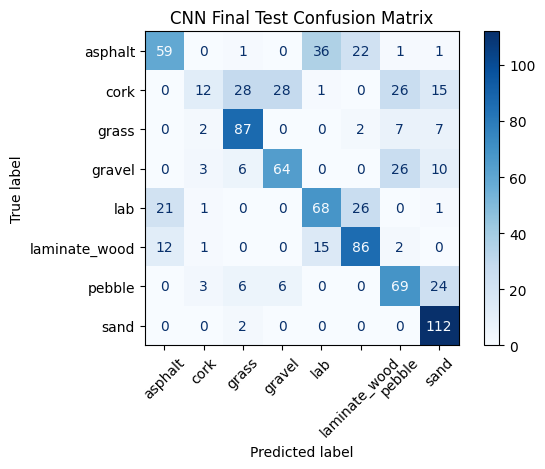

In [11]:

# 1. Evaluate the baseline models on the held-out test set
test_results = []

for name, fitted_model in baseline_models.items():
    predictions = fitted_model.predict(X_test)

    test_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

# 2. Evaluate the best CNN on the test set
model.eval()
cnn_test_preds = []

with torch.no_grad():
    for xb, fb, yb in test_loader:
        logits = model(xb.to(device), fb.to(device))
        cnn_test_preds.extend(
            logits.argmax(dim=1).cpu().numpy()
        )

test_results.append({
    "Model": "CNN",
    "Test Accuracy": accuracy_score(y_test_id, cnn_test_preds),
    "Test Macro F1": f1_score(
        y_test_id, cnn_test_preds, average="macro"
    )
})

# 3. Display the final comparison
test_results_df = pd.DataFrame(test_results).sort_values(
    "Test Accuracy", ascending=False
)

display(test_results_df.reset_index(drop=True))

# 4. CNN classification report
print("\nCNN Test Classification Report:")
print(classification_report(
    y_test_id,
    cnn_test_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# 5. CNN test confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_id,
    cnn_test_preds,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("CNN Final Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:

# Save model comparisons
baseline_results_df.to_csv(
    "/content/validation_model_comparison.csv", index=False
)
test_results_df.to_csv(
    "/content/test_model_comparison.csv", index=False
)

# Save the trained CNN and preprocessing parameters
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "channel_mean": channel_mean,
    "channel_std": channel_std,
    "feature_mean": feature_mean,
    "feature_std": feature_std
}, "/content/terrain_cnn_checkpoint.pth")

print("Saved:")
print("/content/validation_model_comparison.csv")
print("/content/test_model_comparison.csv")
print("/content/terrain_cnn_checkpoint.pth")


Saved:
/content/validation_model_comparison.csv
/content/test_model_comparison.csv
/content/terrain_cnn_checkpoint.pth


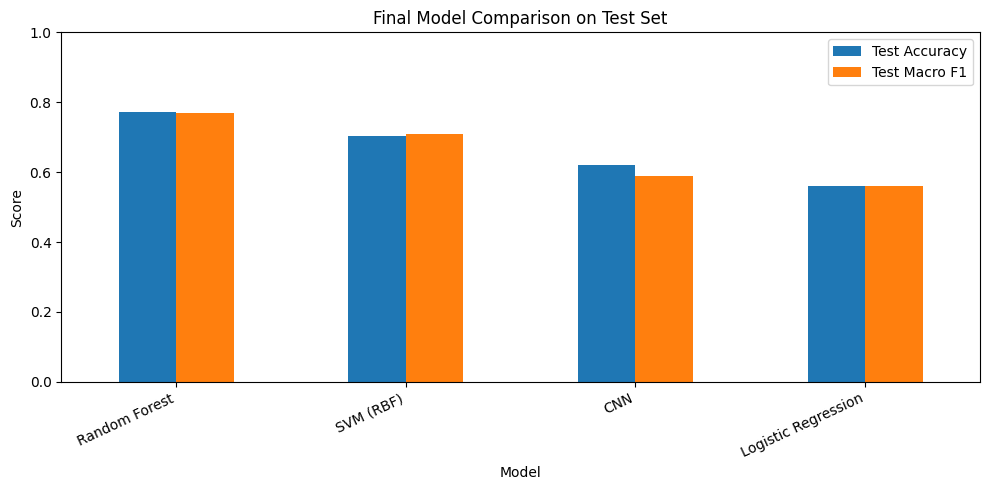

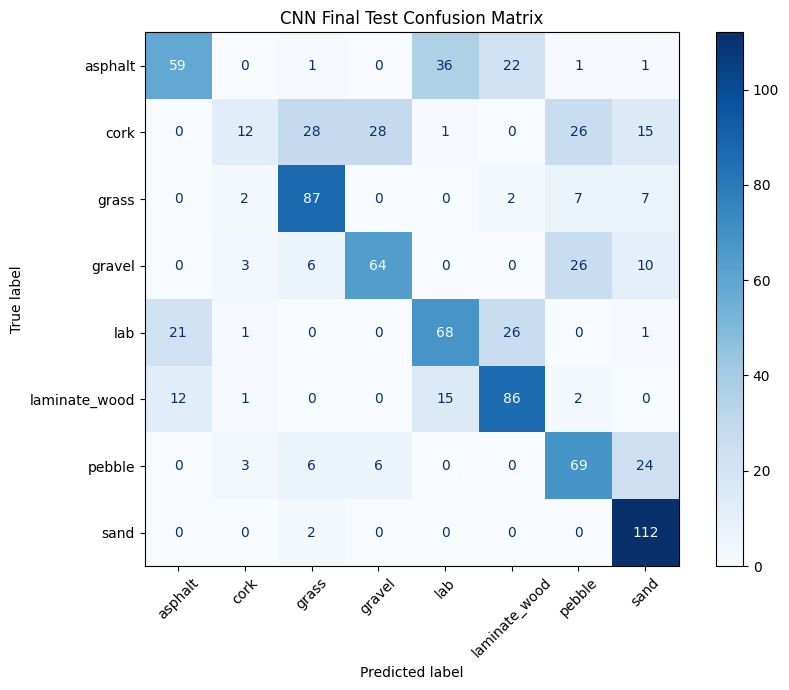

Saved model_comparison.png
Saved cnn_confusion_matrix.png


In [13]:

# Save the model comparison chart
plt.figure(figsize=(10, 5))

plot_df = test_results_df.set_index("Model")[
    ["Test Accuracy", "Test Macro F1"]
]
plot_df.plot(kind="bar", ax=plt.gca())

plt.title("Final Model Comparison on Test Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("/content/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Save the CNN confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test_id,
    cnn_test_preds,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("CNN Final Test Confusion Matrix")
fig.tight_layout()
fig.savefig("/content/cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved model_comparison.png")
print("Saved cnn_confusion_matrix.png")
